In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

# 1. Load the prepared sales dataset
df = pd.read_csv(
    "../data/daily_food_sales.csv",
    parse_dates=["date"]
)

df = df.sort_values("day_number").reset_index(drop=True)

# 2. Recreate lag features
for lag in [1, 7, 14, 28]:
    df[f"lag_{lag}"] = df["units_sold"].shift(lag)

# 3. Recreate rolling features
df["rolling_mean_7"] = (
    df["units_sold"].shift(1).rolling(7).mean()
)

df["rolling_mean_28"] = (
    df["units_sold"].shift(1).rolling(28).mean()
)

# 4. Calendar features
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

df = df.dropna(subset=[
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
])

# 5. Load event information
calendar_events = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=["d", "event_name_1", "event_name_2"]
)

df_events = df.merge(
    calendar_events,
    on="d",
    how="left",
    validate="many_to_one"
)

df_events[["event_name_1", "event_name_2"]] = (
    df_events[["event_name_1", "event_name_2"]]
    .fillna("No_Event")
)

# 6. Define features
numeric_features = [
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

event_features = [
    "day_of_week", "month",
    "event_name_1", "event_name_2"
]

all_features = numeric_features + event_features

# 7. Chronological split
train_events = df_events[
    df_events["day_number"] <= 1773
].copy()

validation_events = df_events[
    df_events["day_number"].between(1774, 1829)
].copy()

# 8. Define preprocessing
event_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         event_features)
    ]
)

print("Initialization successful!")
print("Training rows:", len(train_events))
print("Validation rows:", len(validation_events))


Initialization successful!
Training rows: 1745
Validation rows: 56


In [3]:

from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import numpy as np

quantile_models = {}

# Train lower and upper quantile models
for q in [0.05, 0.95]:

    model = Pipeline([
        ("preprocessor", clone(event_preprocessor)),
        ("model", LGBMRegressor(
            objective="quantile",
            alpha=q,
            n_estimators=200,
            learning_rate=0.05,
            num_leaves=15,
            min_child_samples=20,
            random_state=42,
            verbosity=-1
        ))
    ])

    model.fit(
        train_events[all_features],
        train_events["units_sold"]
    )

    quantile_models[q] = model

# Generate uncertainty bounds
lower = quantile_models[0.05].predict(
    validation_events[all_features]
)

upper = quantile_models[0.95].predict(
    validation_events[all_features]
)

# Enforce nonnegative sales and ordered bounds
lower, upper = (
    np.maximum(0, np.minimum(lower, upper)),
    np.maximum(0, np.maximum(lower, upper))
)

print("Quantile models trained successfully!")


c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

Quantile models trained successfully!


In [4]:

actual = validation_events["units_sold"].to_numpy()

# Percentage of actual values inside predicted intervals
coverage = np.mean(
    (actual >= lower) & (actual <= upper)
) * 100

# Average width of prediction intervals
average_width = np.mean(upper - lower)

print(f"Target coverage: 90.00%")
print(f"Actual coverage: {coverage:.2f}%")
print(f"Average interval width: {average_width:.2f} units")


Target coverage: 90.00%
Actual coverage: 82.14%
Average interval width: 821.46 units


In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Recreate our best point forecasting model
ridge_events = Pipeline([
    ("preprocessor", clone(event_preprocessor)),
    ("model", Ridge(alpha=10.0))
])

# Train Ridge using historical data
ridge_events.fit(
    train_events[all_features],
    train_events["units_sold"]
)

# Generate predictions for validation data
event_predictions = ridge_events.predict(
    validation_events[all_features]
)

print("Ridge predictions generated successfully!")

Ridge predictions generated successfully!


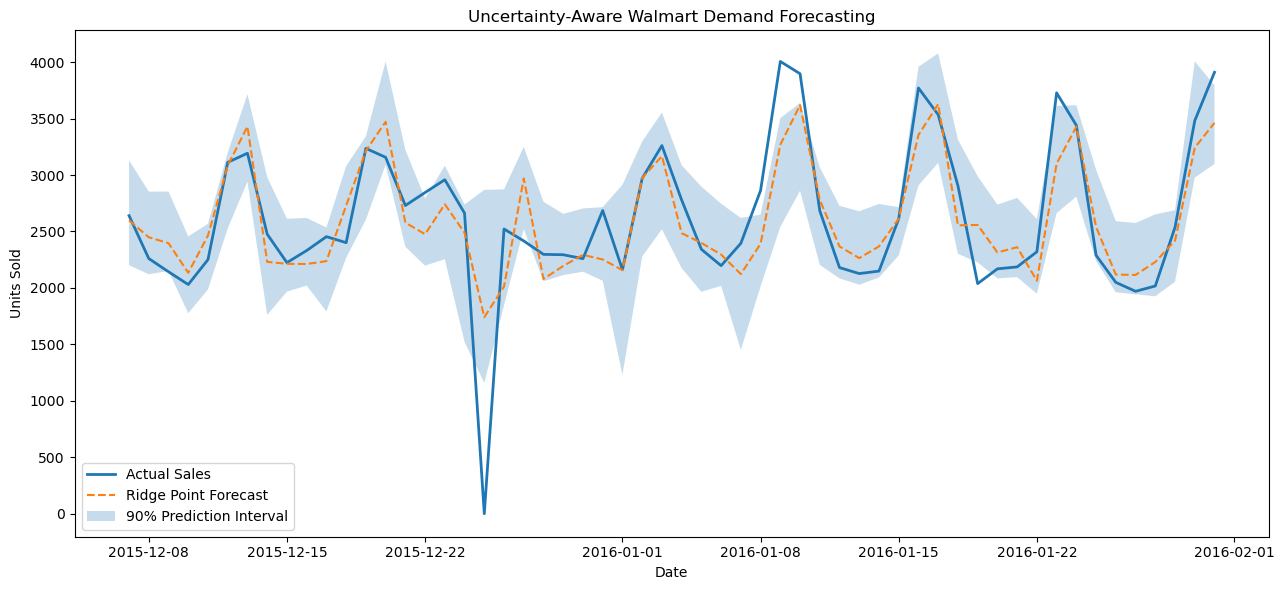

In [9]:
import matplotlib.pyplot as plt

dates = validation_events["date"]
actual = validation_events["units_sold"].to_numpy()

plt.figure(figsize=(13, 6))

# Actual sales
plt.plot(
    dates,
    actual,
    label="Actual Sales",
    linewidth=2
)

# Ridge point forecasts
plt.plot(
    dates,
    event_predictions,
    label="Ridge Point Forecast",
    linestyle="--"
)

# LightGBM prediction intervals
plt.fill_between(
    dates,
    lower,
    upper,
    alpha=0.25,
    label="90% Prediction Interval"
)

plt.title("Uncertainty-Aware Walmart Demand Forecasting")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import numpy as np

coverage = np.mean(
    (actual >= lower) & (actual <= upper)
) * 100

average_width = np.mean(upper - lower)

print(f"Target Coverage: 90.00%")
print(f"Actual Coverage: {coverage:.2f}%")
print(f"Average Interval Width: {average_width:.2f} units")

Target Coverage: 90.00%
Actual Coverage: 82.14%
Average Interval Width: 821.46 units


In [11]:

# Separate calibration data
calibration_events = df_events[
    df_events["day_number"].between(1830, 1885)
].copy()

X_cal = calibration_events[all_features]
y_cal = calibration_events["units_sold"].to_numpy()

# Predict lower and upper quantiles
cal_lower_raw = quantile_models[0.05].predict(X_cal)
cal_upper_raw = quantile_models[0.95].predict(X_cal)

# Ensure valid nonnegative bounds
cal_lower = np.maximum(
    0, np.minimum(cal_lower_raw, cal_upper_raw)
)

cal_upper = np.maximum(
    0, np.maximum(cal_lower_raw, cal_upper_raw)
)

print("Calibration observations:", len(y_cal))


Calibration observations: 56


In [12]:

calibration_coverage = np.mean(
    (y_cal >= cal_lower) &
    (y_cal <= cal_upper)
) * 100

calibration_width = np.mean(
    cal_upper - cal_lower
)

print(f"Raw calibration coverage: {calibration_coverage:.2f}%")
print(f"Raw average width: {calibration_width:.2f} units")


Raw calibration coverage: 87.50%
Raw average width: 831.31 units


In [13]:

# Desired miscoverage rate
alpha = 0.10

# Calculate nonconformity scores
scores = np.maximum.reduce([
    cal_lower - y_cal,
    y_cal - cal_upper,
    np.zeros_like(y_cal)
])

# Finite-sample conformal quantile
n = len(scores)
k = int(np.ceil((n + 1) * (1 - alpha)))

q_hat = np.sort(scores)[k - 1]

print(f"Calibration observations: {n}")
print(f"Conformal rank: {k}")
print(f"Conformal adjustment: {q_hat:.2f} units")


Calibration observations: 56
Conformal rank: 52
Conformal adjustment: 31.48 units


In [14]:

# Final evaluation period
test_events = df_events[
    df_events["day_number"].between(1886, 1941)
].copy()

X_test = test_events[all_features]
y_test = test_events["units_sold"].to_numpy()

# Original quantile predictions
test_lower_raw = quantile_models[0.05].predict(X_test)
test_upper_raw = quantile_models[0.95].predict(X_test)

# Ensure ordered, nonnegative bounds
test_lower = np.maximum(
    0, np.minimum(test_lower_raw, test_upper_raw)
)

test_upper = np.maximum(
    0, np.maximum(test_lower_raw, test_upper_raw)
)

# Apply conformal adjustment
calibrated_lower = np.maximum(0, test_lower - q_hat)
calibrated_upper = test_upper + q_hat

print("Final evaluation observations:", len(y_test))
print(f"Conformal adjustment: {q_hat:.2f} units")


Final evaluation observations: 56
Conformal adjustment: 31.48 units


In [15]:

# Original interval coverage
original_coverage = np.mean(
    (y_test >= test_lower) &
    (y_test <= test_upper)
) * 100

# Calibrated interval coverage
calibrated_coverage = np.mean(
    (y_test >= calibrated_lower) &
    (y_test <= calibrated_upper)
) * 100

# Interval widths
original_width = np.mean(test_upper - test_lower)

calibrated_width = np.mean(
    calibrated_upper - calibrated_lower
)

print("=== ORIGINAL QUANTILE MODEL ===")
print(f"Coverage: {original_coverage:.2f}%")
print(f"Average width: {original_width:.2f} units")

print("\n=== CONFORMAL CALIBRATION ===")
print(f"Coverage: {calibrated_coverage:.2f}%")
print(f"Average width: {calibrated_width:.2f} units")

print("\n=== CHANGE ===")
print(
    f"Coverage change: "
    f"{calibrated_coverage - original_coverage:+.2f} pp"
)
print(
    f"Width change: "
    f"{calibrated_width - original_width:+.2f} units"
)


=== ORIGINAL QUANTILE MODEL ===
Coverage: 89.29%
Average width: 756.89 units

=== CONFORMAL CALIBRATION ===
Coverage: 91.07%
Average width: 819.85 units

=== CHANGE ===
Coverage change: +1.79 pp
Width change: +62.96 units


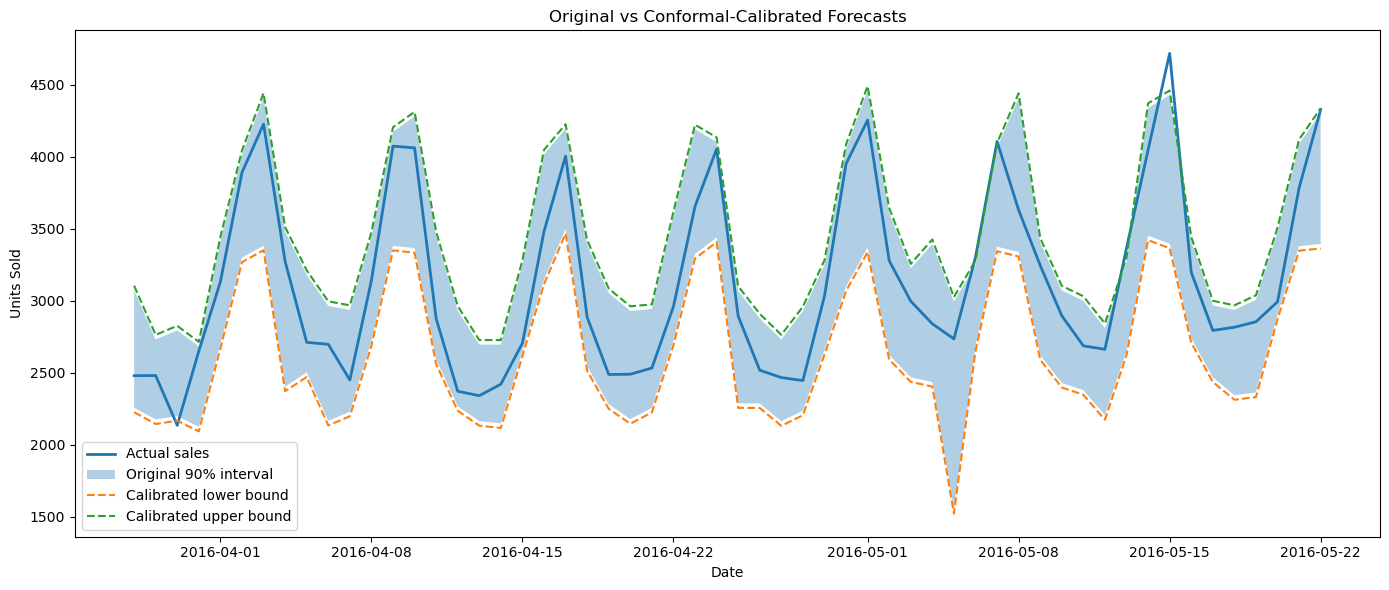

In [16]:

import matplotlib.pyplot as plt

dates = test_events["date"]

plt.figure(figsize=(14, 6))

# Actual observations
plt.plot(
    dates,
    y_test,
    label="Actual sales",
    linewidth=2
)

# Original interval
plt.fill_between(
    dates,
    test_lower,
    test_upper,
    alpha=0.35,
    label="Original 90% interval"
)

# Calibrated boundaries
plt.plot(
    dates,
    calibrated_lower,
    linestyle="--",
    label="Calibrated lower bound"
)

plt.plot(
    dates,
    calibrated_upper,
    linestyle="--",
    label="Calibrated upper bound"
)

plt.title("Original vs Conformal-Calibrated Forecasts")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()


In [17]:

def interval_score(actual, lower, upper, alpha=0.10):
    width = upper - lower

    below_penalty = (
        (2 / alpha) *
        (lower - actual) *
        (actual < lower)
    )

    above_penalty = (
        (2 / alpha) *
        (actual - upper) *
        (actual > upper)
    )

    return np.mean(
        width + below_penalty + above_penalty
    )

original_score = interval_score(
    y_test, test_lower, test_upper
)

calibrated_score = interval_score(
    y_test, calibrated_lower, calibrated_upper
)

print(f"Original interval score: {original_score:.2f}")
print(f"Calibrated interval score: {calibrated_score:.2f}")


Original interval score: 961.00
Calibrated interval score: 959.71


In [18]:

from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# Assumed financial costs
overstock_cost = 2
understock_cost = 8

# Optimal target quantile
optimal_quantile = (
    understock_cost /
    (understock_cost + overstock_cost)
)

print(f"Optimal demand quantile: {optimal_quantile:.2f}")

# Train quantile regression
inventory_model = Pipeline([
    ("preprocessor", clone(event_preprocessor)),
    ("model", LGBMRegressor(
        objective="quantile",
        alpha=optimal_quantile,
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=20,
        random_state=42,
        verbosity=-1
    ))
])

inventory_model.fit(
    train_events[all_features],
    train_events["units_sold"]
)

print("Inventory forecasting model trained!")


Optimal demand quantile: 0.80
Inventory forecasting model trained!


In [19]:

# Recreate the Ridge model
ridge_inventory = Pipeline([
    ("preprocessor", clone(event_preprocessor)),
    ("model", Ridge(alpha=10.0))
])

ridge_inventory.fit(
    train_events[all_features],
    train_events["units_sold"]
)

# Actual historical sales
actual = test_events["units_sold"].to_numpy()

# Strategy A: Last week's sales
naive_order = np.ceil(
    np.maximum(0, test_events["lag_7"].to_numpy())
)

# Strategy B: Ridge point forecast
ridge_order = np.ceil(
    np.maximum(0, ridge_inventory.predict(
        test_events[all_features]
    ))
)

# Strategy C: ML 80th percentile
quantile_order = np.ceil(
    np.maximum(0, inventory_model.predict(
        test_events[all_features]
    ))
)

# Calculate hypothetical decision cost
def inventory_cost(actual, order):
    overstock = np.maximum(order - actual, 0)
    understock = np.maximum(actual - order, 0)

    return (
        overstock_cost * overstock
        + understock_cost * understock
    )

strategies = {
    "Seasonal Naive": naive_order,
    "Ridge Point Forecast": ridge_order,
    "Quantile ML (80%)": quantile_order
}

results = []

for name, order in strategies.items():
    costs = inventory_cost(actual, order)

    results.append({
        "Strategy": name,
        "Total Cost ($)": costs.sum(),
        "Average Daily Cost ($)": costs.mean(),
        "Shortage Units": np.maximum(
            actual - order, 0
        ).sum(),
        "Surplus Units": np.maximum(
            order - actual, 0
        ).sum()
    })

comparison = pd.DataFrame(results)
comparison = comparison.sort_values("Total Cost ($)")

print(comparison.to_string(index=False))


            Strategy  Total Cost ($)  Average Daily Cost ($)  Shortage Units  Surplus Units
   Quantile ML (80%)         27780.0              496.071429          1694.0         7114.0
Ridge Point Forecast         50534.0              902.392857          5572.0         2979.0
      Seasonal Naive         73034.0             1304.178571          7529.0         6401.0


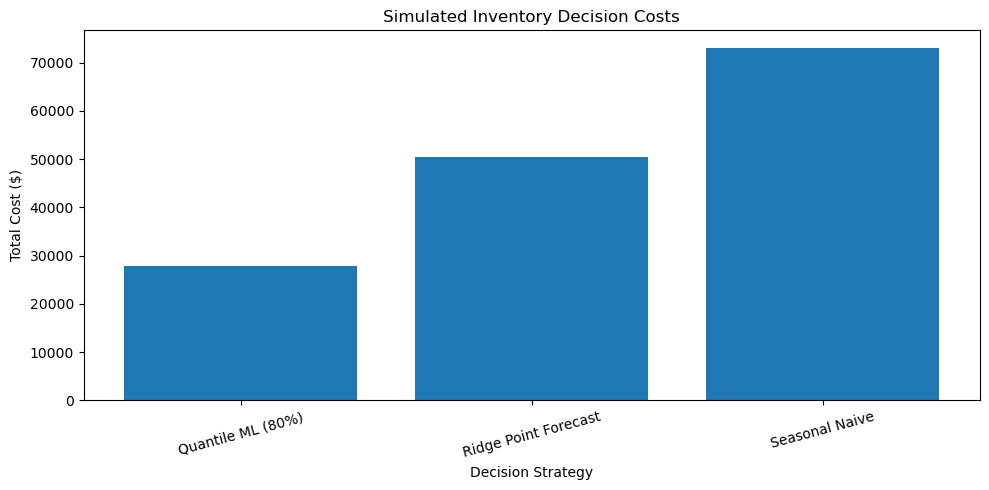

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Strategy"],
    comparison["Total Cost ($)"]
)

plt.title("Simulated Inventory Decision Costs")
plt.ylabel("Total Cost ($)")
plt.xlabel("Decision Strategy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [22]:

# Sort data chronologically
history = df_events.sort_values("day_number").copy()

# Collect the same weekday from the previous 8 weeks
past_weekdays = pd.concat(
    [
        history["units_sold"].shift(7 * week)
        for week in range(1, 9)
    ],
    axis=1
)

# Historical 80th-percentile demand
history["seasonal_q80"] = past_weekdays.quantile(
    0.80,
    axis=1
)

# Evaluate on the same final period
seasonal_test = history[
    history["day_number"].between(1886, 1941)
].copy()

assert np.array_equal(
    seasonal_test["day_number"].to_numpy(),
    test_events["day_number"].to_numpy()
)

# Convert predictions into order quantities
seasonal_q80_order = np.ceil(
    seasonal_test["seasonal_q80"]
    .clip(lower=0)
    .to_numpy()
)

# Calculate business costs using the existing function
seasonal_q80_costs = inventory_cost(
    y_test,
    seasonal_q80_order
)

# Add the new strategy to our comparison
new_result = pd.DataFrame([{
    "Strategy": "Seasonal Quantile (80%)",
    "Total Cost ($)": seasonal_q80_costs.sum(),
    "Average Daily Cost ($)": seasonal_q80_costs.mean(),
    "Shortage Units": np.maximum(
        y_test - seasonal_q80_order, 0
    ).sum(),
    "Surplus Units": np.maximum(
        seasonal_q80_order - y_test, 0
    ).sum()
}])

updated_comparison = pd.concat(
    [comparison, new_result],
    ignore_index=True
)

updated_comparison = updated_comparison.sort_values(
    "Total Cost ($)"
)

print(updated_comparison.to_string(index=False))


               Strategy  Total Cost ($)  Average Daily Cost ($)  Shortage Units  Surplus Units
      Quantile ML (80%)         27780.0              496.071429          1694.0         7114.0
Seasonal Quantile (80%)         45852.0              818.785714          4119.0         6450.0
   Ridge Point Forecast         50534.0              902.392857          5572.0         2979.0
         Seasonal Naive         73034.0             1304.178571          7529.0         6401.0
